# Machine Learning Lab File
**Name:** Adrika Banerjee  **Course:** B.Tech CSE, 3rd Year  **University:** Sister Nivedita University
**Platform:** Kaggle Notebook (Python 3, scikit-learn)

| No. | Assignment | Algorithm | Dataset |
|---|---|---|---|
| 1 | Predict CO2 emission | Simple Linear Regression | fuel_consumption_dataset.csv |
| 2 | Predict house price | Multiple Linear Regression (Pipeline + OneHotEncoder) | housing_price_dataset.csv |
| 3 | Predict house price with regularization | Lasso (L1) & Ridge (L2) + GridSearchCV | housing_price_dataset.csv |
| 4 | Classify customer gender | Support Vector Machine (5 kernels) | Mall_Customers.csv |
| 5 | Classify customer gender | Decision Tree | Mall_Customers.csv |
| 6 | Predict the right drug for a patient | Decision Tree (entropy) | drug200.csv |
| 7 | Classify tumour as benign / malignant | Logistic Regression | samples_cancer.csv |
| 8 | Classify customer gender | Naive Bayes (Multinomial, Gaussian, Bernoulli) | Mall_Customers.csv |

> Datasets: Kaggle input `adrikabanerjee/ml-dataset`.

---
# Assignment 1 — Linear Regression: CO2 Emission

**Aim:** Perform linear regression to predict CO2 emission of a car (`fuel_consumption_dataset.csv`). Evaluate the model using MAE, MSE, RMSE and R², and plot Actual vs Predicted values.

**Theory:**
Linear regression fits a straight line **ŷ = m·x + c** through the data so that the error between actual (y) and predicted (ŷ) values is minimum (least squares).
Here x = `ENGINESIZE`, y = `CO2EMISSIONS` — bigger engines burn more fuel, so they emit more CO2.

| Metric | Formula | Meaning |
|---|---|---|
| MAE | mean(\|y − ŷ\|) | average error, same unit as y |
| MSE | mean((y − ŷ)²) | punishes big errors more |
| RMSE | √MSE | MSE brought back to y's unit |
| R² | 1 − SS_res / SS_tot | fraction of variation explained (1 = perfect) |

**Steps:** load data → choose feature & target → split 80/20 → train `LinearRegression` → predict → metrics → plot.

In [142]:
# [1] Load dataset and separate target
import pandas as pd
df = pd.read_csv("/kaggle/input/datasets/adrikabanerjee/ml-dataset/fuel_consumption_dataset.csv")
y = df["CO2EMISSIONS"]
x = df.drop("CO2EMISSIONS", axis=1)
print("Extracted Features:")
print(x.columns)

Extracted Features:
Index(['MODELYEAR', 'MAKE', 'MODEL', 'VEHICLECLASS', 'ENGINESIZE', 'CYLINDERS',
       'TRANSMISSION', 'FUELTYPE', 'FUELCONSUMPTION_CITY',
       'FUELCONSUMPTION_HWY', 'FUELCONSUMPTION_COMB',
       'FUELCONSUMPTION_COMB_MPG'],
      dtype='object')


In [143]:
# [2] Use only ENGINESIZE as the feature
x = df[["ENGINESIZE"]]
print(x.head())
print(y.head())

   ENGINESIZE
0         2.0
1         2.4
2         1.5
3         3.5
4         3.5
0    196
1    221
2    136
3    255
4    244
Name: CO2EMISSIONS, dtype: int64


In [144]:
# [3] Train-test split
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

In [145]:
# [4] Train the model
from sklearn.linear_model import LinearRegression
model = LinearRegression()
model.fit(x_train, y_train)

LinearRegression()

In [146]:
# [5] Predict and evaluate
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
y_pred = model.predict(x_test)
print("MAE:", mean_absolute_error(y_test, y_pred))
print("MSE:", mean_squared_error(y_test, y_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred)))
print("R2 Score:", r2_score(y_test, y_pred))

MAE: 24.09725741170784
MSE: 985.9381692274999
RMSE: 31.399652374309813
R2 Score: 0.7615595731934373


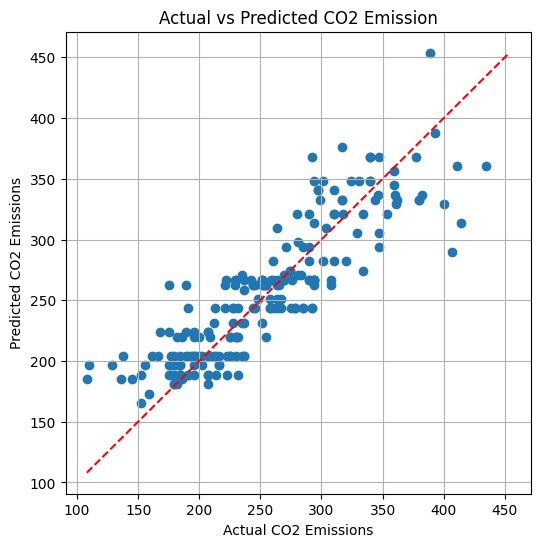

In [147]:
# [6] Actual vs Predicted plot
import matplotlib.pyplot as plt
plt.figure(figsize=(6, 6))
plt.scatter(y_test, y_pred)
min_val = min(y_test.min(), y_pred.min())
max_val = max(y_test.max(), y_pred.max())
plt.plot([min_val, max_val], [min_val, max_val], "r--")
plt.xlabel("Actual CO2 Emissions")
plt.ylabel("Predicted CO2 Emissions")
plt.title("Actual vs Predicted CO2 Emission")
plt.grid(True)
plt.show()

**Output observed in class:**

| MAE | MSE | RMSE | R² |
|---|---|---|---|
| 24.10 | 985.94 | 31.40 | 0.7616 |

**Conclusion:** With only engine size as input, the model explains about **76%** of the variation in CO2 emission. The points lie close to the red line (perfect prediction), so engine size is a strong predictor. Adding features such as `FUELCONSUMPTION_COMB` and `CYLINDERS` would improve R² further.

---
# Assignment 2 — Linear Regression: Housing Price

**Aim:** Perform linear regression to predict housing price. Evaluate with MAE, RMSE and R², and plot Actual vs Predicted values.

**Theory:**
*Multiple* linear regression: **ŷ = b₀ + b₁x₁ + b₂x₂ + … + bₙxₙ** (one weight per feature).
The model only understands numbers, so text (categorical) columns are converted using **One-Hot Encoding** — each category becomes its own 0/1 column.

| Tool | Job |
|---|---|
| `ColumnTransformer` | apply OneHotEncoder only to text columns; `remainder="passthrough"` keeps number columns as they are |
| `Pipeline` | chains preprocessing + model, so `fit` / `predict` run both steps automatically |
| `handle_unknown="ignore"` | a category seen only in test data doesn't crash the model |

**Steps:** load → X/y → find numeric & categorical columns → ColumnTransformer → Pipeline → split → fit → predict → metrics → plot.

In [148]:
# [1] Load dataset, separate target
import pandas as pd
df = pd.read_csv("/kaggle/input/datasets/adrikabanerjee/ml-dataset/housing_price_dataset.csv")
y = df["price"]
X = df.drop("price", axis=1)
print("Extract Features:")
print(X.columns)

Extract Features:
Index(['area', 'bedrooms', 'bathrooms', 'stories', 'mainroad', 'guestroom',
       'basement', 'hotwaterheating', 'airconditioning', 'parking', 'prefarea',
       'furnishingstatus'],
      dtype='object')


In [149]:
# [2] Imports
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [150]:
# [3] Numeric and categorical columns
num_cols = X.select_dtypes(include="number").columns
cat_cols = X.select_dtypes(exclude="number").columns
print("Numeric    :", list(num_cols))
print("Categorical:", list(cat_cols))

Numeric    : ['area', 'bedrooms', 'bathrooms', 'stories', 'parking']
Categorical: ['mainroad', 'guestroom', 'basement', 'hotwaterheating', 'airconditioning', 'prefarea', 'furnishingstatus']


In [151]:
# [4] Preprocessor: one-hot encode categorical, pass numeric through
preprocessor = ColumnTransformer(
    transformers=[
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols)
    ],
    remainder="passthrough"
)

In [152]:
# [5] Pipeline
model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", LinearRegression())
])

In [153]:
# [6] Train-test split and fit
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
model.fit(X_train, y_train)

/usr/local/lib/python3.13/dist-packages/sklearn/compose/_column_transformer.py:1667: FutureWarning: 
The format of the columns of the 'remainder' transformer in ColumnTransformer.transformers_ will change in version 1.7 to match the format of the other transformers.
At the moment the remainder columns are stored as indices (of type int). With the same ColumnTransformer configuration, in the future they will be stored as column names (of type str).
To use the new behavior now and suppress this warning, use ColumnTransformer(force_int_remainder_cols=False).

  warnings.warn(


Pipeline(steps=[('preprocessor',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  Index(['mainroad', 'guestroom', 'basement', 'hotwaterheating',
       'airconditioning', 'prefarea', 'furnishingstatus'],
      dtype='object'))])),
                ('regressor', LinearRegression())])

In [154]:
# [7] Predict and evaluate
y_pred = model.predict(X_test)
mae = mean_absolute_error(y_test, y_pred)
rmse = mean_squared_error(y_test, y_pred) ** 0.5
r2 = r2_score(y_test, y_pred)
print("MAE:", mae)
print("RMSE:", rmse)
print("R2:", r2)

MAE: 970043.4039201646
RMSE: 1324506.9600914537
R2: 0.6529242642153106


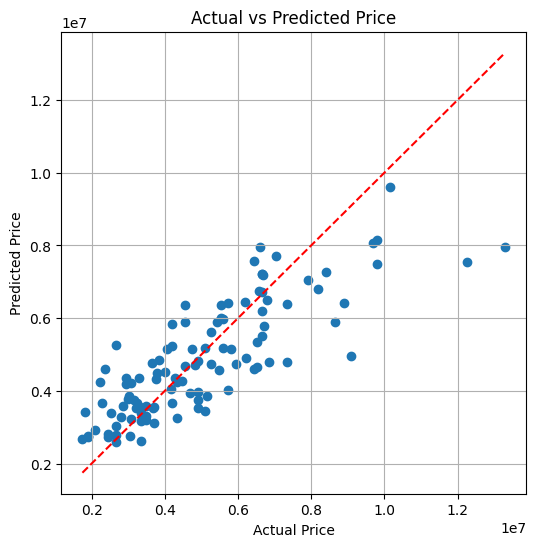

In [155]:
# [8] Actual vs Predicted plot
plt.figure(figsize=(6, 6))
plt.scatter(y_test, y_pred)
min_val = min(y_test.min(), y_pred.min())
max_val = max(y_test.max(), y_pred.max())
plt.plot([min_val, max_val], [min_val, max_val], "r--")
plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title("Actual vs Predicted Price")
plt.grid(True)
plt.show()

**Output:**

| MAE | RMSE | R² |
|---|---|---|
| 970043.40 | 1324506.96 | 0.6529 |

**Conclusion:** The pipeline model explains about **65%** of the variation in house price. The average error is about ₹9.7 lakh (MAE), and RMSE is ₹13.2 lakh, against house prices of up to ₹1.33 crore in the dataset. That is a moderate fit: price also depends on things the dataset doesn't record, such as exact location and condition, and there are only 545 houses. The Pipeline + ColumnTransformer approach converted the 7 text columns (`mainroad`, `guestroom`, `basement`, `hotwaterheating`, `airconditioning`, `prefarea`, `furnishingstatus`) automatically with One-Hot Encoding.

---
# Assignment 3 — Lasso (L1) and Ridge (L2) Regularization: House Price

**Aim:** Perform linear regression with L1 (Lasso) and L2 (Ridge) regularization to predict house price. Use hyper-parameter tuning for the best result, evaluate with MAE, MSE, RMSE, R², and plot Actual vs Predicted for both models.

**Theory:**
Regularization adds a **penalty on large weights** to the loss, so the model doesn't overfit.

| | Lasso (L1) | Ridge (L2) |
|---|---|---|
| Loss | MSE + α·Σ\|w\| | MSE + α·Σw² |
| Effect | can make some weights exactly **0** → feature selection | shrinks all weights, none become 0 |
| Good when | many useless features | many correlated features |

**α (alpha)** controls penalty strength: too small → same as normal regression; too big → underfits.
**GridSearchCV** tries every α in a list with **5-fold cross-validation** and keeps the one with the best R².
**StandardScaler** is needed because the penalty treats all weights equally, so features must be on the same scale.

Text columns (yes/no, `furnishingstatus`) are one-hot encoded with a **ColumnTransformer**, and number columns are scaled.

**Steps:** load → X/y → ColumnTransformer (scale numbers + one-hot text) → split → α list → Pipeline(preprocessor + model) → GridSearchCV → evaluate → compare → plot.

In [156]:
# [1] Imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Lasso, Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [157]:
# [2] Load dataset
df = pd.read_csv("/kaggle/input/datasets/adrikabanerjee/ml-dataset/housing_price_dataset.csv")
print("Dataset Shape:", df.shape)
print(df.head())

Dataset Shape: (545, 13)
      price  area  bedrooms  bathrooms  stories mainroad guestroom basement  \
0  13300000  7420         4          2        3      yes        no       no   
1  12250000  8960         4          4        4      yes        no       no   
2  12250000  9960         3          2        2      yes        no      yes   
3  12215000  7500         4          2        2      yes        no      yes   
4  11410000  7420         4          1        2      yes       yes      yes   

  hotwaterheating airconditioning  parking prefarea furnishingstatus  
0              no             yes        2      yes        furnished  
1              no             yes        3       no        furnished  
2              no              no        2      yes   semi-furnished  
3              no             yes        3      yes        furnished  
4              no             yes        2       no        furnished  


In [158]:
# [3] Features and target
X = df.drop(columns=["price"])
y = df["price"]

# Scale number columns, one-hot encode text columns (yes/no, furnishingstatus)
# drop="first": keep one 0/1 column per yes/no feature (yes+no columns would duplicate info)
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
num_cols = X.select_dtypes(include="number").columns
cat_cols = X.select_dtypes(exclude="number").columns
preprocessor = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(drop="first", handle_unknown="ignore"), cat_cols)
])

In [159]:
# [4] Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)
print("Training Samples:", X_train.shape[0])
print("Testing Samples:", X_test.shape[0])

Training Samples: 436
Testing Samples: 109


In [160]:
# [5] Alpha values to search (10^-2 to 10^6, 30 values; prices are in lakhs, so a wide range is needed)
alphas = np.logspace(-2, 6, 30)

In [161]:
# [6] Lasso pipeline + GridSearchCV
lasso_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", Lasso(max_iter=100000, random_state=42))
])
lasso_grid = GridSearchCV(
    lasso_pipeline,
    param_grid={"model__alpha": alphas},
    cv=5,
    scoring="r2",
    n_jobs=-1
)

In [162]:
# [7] Train Lasso and evaluate
lasso_grid.fit(X_train, y_train)
lasso_best_alpha = lasso_grid.best_params_["model__alpha"]
lasso_pred = lasso_grid.predict(X_test)
lasso_mae = mean_absolute_error(y_test, lasso_pred)
lasso_mse = mean_squared_error(y_test, lasso_pred)
lasso_rmse = np.sqrt(lasso_mse)
lasso_r2 = r2_score(y_test, lasso_pred)

print("\n==== LASSO REGRESSION ====")
print("Best Alpha:", lasso_best_alpha)
print("MAE:", lasso_mae)
print("MSE:", lasso_mse)
print("RMSE:", lasso_rmse)
print("R2 Score:", lasso_r2)
print("CV R2:", lasso_grid.best_score_)


==== LASSO REGRESSION ====
Best Alpha: 923.6708571873866
MAE: 970628.1262834369
MSE: 1757216564289.8618
RMSE: 1325600.4542432316
R2 Score: 0.6523509460462248
CV R2: 0.6470706470593596


In [163]:
# [8] Ridge pipeline + GridSearchCV, train and evaluate
ridge_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", Ridge())
])
ridge_grid = GridSearchCV(
    ridge_pipeline,
    param_grid={"model__alpha": alphas},
    cv=5,
    scoring="r2",
    n_jobs=-1
)
ridge_grid.fit(X_train, y_train)
ridge_best_alpha = ridge_grid.best_params_["model__alpha"]
ridge_pred = ridge_grid.predict(X_test)
ridge_mae = mean_absolute_error(y_test, ridge_pred)
ridge_mse = mean_squared_error(y_test, ridge_pred)
ridge_rmse = np.sqrt(ridge_mse)
ridge_r2 = r2_score(y_test, ridge_pred)

print("\n==== RIDGE REGRESSION ====")
print("Best Alpha:", ridge_best_alpha)
print("MAE:", ridge_mae)
print("MSE:", ridge_mse)
print("RMSE:", ridge_rmse)
print("R2 Score:", ridge_r2)
print("CV R2:", ridge_grid.best_score_)


==== RIDGE REGRESSION ====
Best Alpha: 5.736152510448681
MAE: 976272.8755289739
MSE: 1776954770380.2651
RMSE: 1333024.6698318322
R2 Score: 0.6484459244265097
CV R2: 0.6485739919486064


In [164]:
# [9] Model comparison
results = pd.DataFrame({
    "Model": ["Lasso (L1)", "Ridge (L2)"],
    "Best Alpha": [lasso_best_alpha, ridge_best_alpha],
    "MAE": [lasso_mae, ridge_mae],
    "MSE": [lasso_mse, ridge_mse],
    "RMSE": [lasso_rmse, ridge_rmse],
    "R2": [lasso_r2, ridge_r2]
})
print("\n==== MODEL COMPARISON ====")
print(results)


==== MODEL COMPARISON ====
        Model  Best Alpha            MAE           MSE          RMSE        R2
0  Lasso (L1)  923.670857  970628.126283  1.757217e+12  1.325600e+06  0.652351
1  Ridge (L2)    5.736153  976272.875529  1.776955e+12  1.333025e+06  0.648446


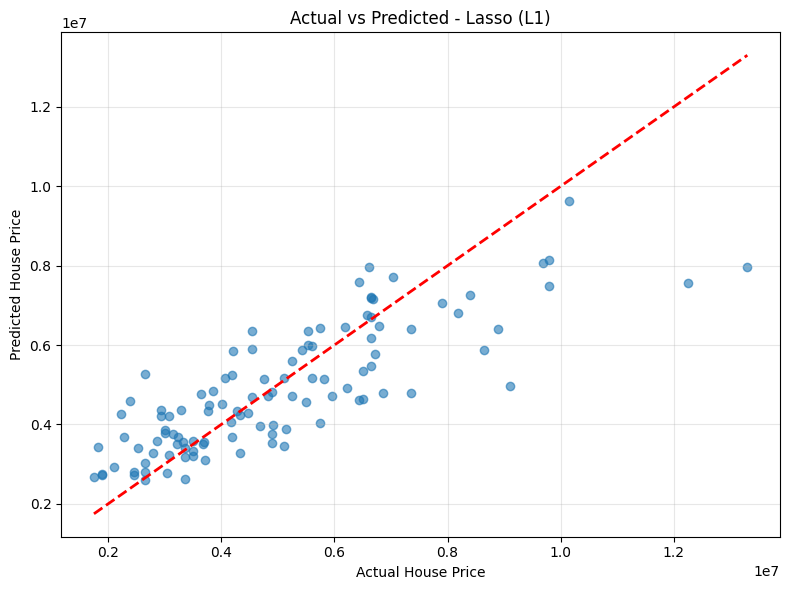

In [165]:
# [10] Actual vs Predicted - Lasso
plt.figure(figsize=(8, 6))
plt.scatter(y_test, lasso_pred, alpha=0.6)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], "r--", linewidth=2)
plt.xlabel("Actual House Price")
plt.ylabel("Predicted House Price")
plt.title("Actual vs Predicted - Lasso (L1)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

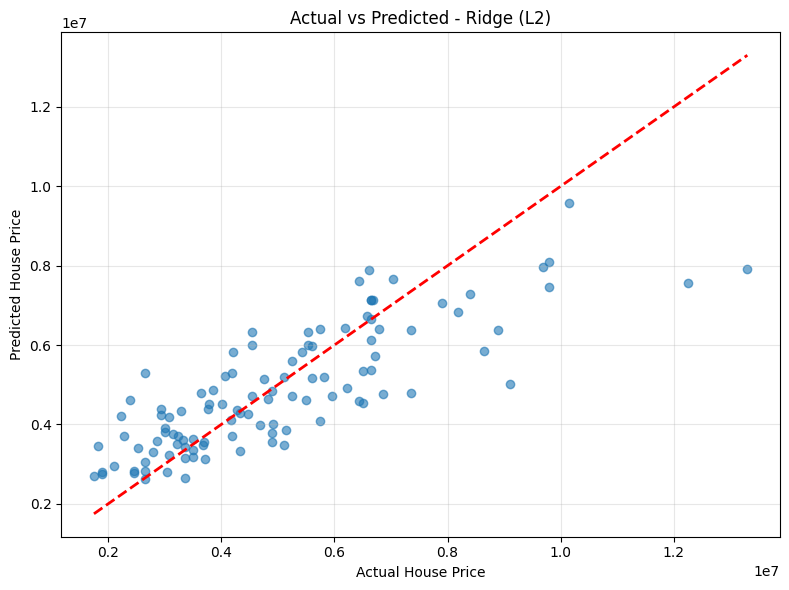

In [166]:
# [11] Actual vs Predicted - Ridge
plt.figure(figsize=(8, 6))
plt.scatter(y_test, ridge_pred, alpha=0.6)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], "r--", linewidth=2)
plt.xlabel("Actual House Price")
plt.ylabel("Predicted House Price")
plt.title("Actual vs Predicted - Ridge (L2)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

**Output** (copy the values from the comparison table printed above):

| Model | Best α | MAE | RMSE | R² | CV R² |
|---|---|---|---|---|---|
| Lasso (L1) | | | | | |
| Ridge (L2) | | | | | |

**Conclusion:** Lasso and Ridge give an R² close to plain linear regression (Assignment 2, R² = 0.653). With 436 training houses and only 12 features, the plain model was not overfitting much, so the penalty has little to correct. GridSearchCV with 5-fold cross-validation picked the α that gave the best average R². The CV R² is close to the test R², which shows the result is stable and not a lucky split.

---
# Assignment 4 — Implementation of SVM (Support Vector Machine)

**Aim:** Classify a mall customer's gender from Age, Annual Income and Spending Score using SVM with different kernels, and compare them with the confusion matrix and classification report.

**Theory:**
SVM finds the boundary (hyperplane) that separates the classes with the **maximum margin**: the widest gap between the boundary and the nearest points of each class (the *support vectors*).
When the data can't be separated by a straight line, a **kernel** maps it into a higher dimension where it can.

| Kernel | Boundary shape |
|---|---|
| `linear` | straight line / flat plane |
| `poly` (degree d) | curved, polynomial of degree d |
| `rbf` | flexible, circle-like regions (default) |
| `sigmoid` | S-shaped, like a neural network neuron |

**Reading the report:** Precision = of those predicted X, how many really were X. Recall = of all real X, how many we caught. F1 = harmonic mean of the two. Support = number of test samples in that class.

**Steps:** load → X/y → split → for each kernel: train `SVC` → predict → confusion matrix + report.

In [167]:
# [1] Imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [168]:
# [2] Load dataset: predict Gender from Age, Annual Income, Spending Score
dataset = pd.read_csv("/kaggle/input/datasets/adrikabanerjee/ml-dataset/Mall_Customers.csv")
dataset = dataset.rename(columns={"Gender": "Genre"})   # some versions name it 'Gender'
X = dataset.drop(["CustomerID", "Genre"], axis=1)
y = dataset["Genre"]

In [169]:
# [3] Train-test split
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)

In [170]:
# [4] Linear kernel
from sklearn.svm import SVC
classifier = SVC(kernel="linear")
classifier.fit(X_train, y_train)
y_pred = classifier.predict(X_test)

In [171]:
# [5] Evaluation - Linear
from sklearn.metrics import classification_report, confusion_matrix
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))
print("---------------------------------")
print("---------------------------------")
print("Performance Evaluation:")
print(classification_report(y_test, y_pred, zero_division=0))

Confusion Matrix:
[[21  0]
 [19  0]]
---------------------------------
---------------------------------
Performance Evaluation:
              precision    recall  f1-score   support

      Female       0.53      1.00      0.69        21
        Male       0.00      0.00      0.00        19

    accuracy                           0.53        40
   macro avg       0.26      0.50      0.34        40
weighted avg       0.28      0.53      0.36        40



In [172]:
# [6] Polynomial kernel, degree 3
classifier = SVC(kernel="poly", degree=3)
classifier.fit(X_train, y_train)
y_pred = classifier.predict(X_test)

In [173]:
# [7] Evaluation - Polynomial (degree 3)
from sklearn.metrics import classification_report, confusion_matrix
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))
print("---------------------------------")
print("---------------------------------")
print("Performance Evaluation:")
print(classification_report(y_test, y_pred, zero_division=0))

Confusion Matrix:
[[20  1]
 [15  4]]
---------------------------------
---------------------------------
Performance Evaluation:
              precision    recall  f1-score   support

      Female       0.57      0.95      0.71        21
        Male       0.80      0.21      0.33        19

    accuracy                           0.60        40
   macro avg       0.69      0.58      0.52        40
weighted avg       0.68      0.60      0.53        40



In [174]:
# [8] Polynomial kernel, degree 2
classifier = SVC(kernel="poly", degree=2)
classifier.fit(X_train, y_train)
y_pred = classifier.predict(X_test)

In [175]:
# [9] Evaluation - Polynomial (degree 2)
from sklearn.metrics import classification_report, confusion_matrix
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))
print("---------------------------------")
print("---------------------------------")
print("Performance Evaluation:")
print(classification_report(y_test, y_pred, zero_division=0))

Confusion Matrix:
[[21  0]
 [19  0]]
---------------------------------
---------------------------------
Performance Evaluation:
              precision    recall  f1-score   support

      Female       0.53      1.00      0.69        21
        Male       0.00      0.00      0.00        19

    accuracy                           0.53        40
   macro avg       0.26      0.50      0.34        40
weighted avg       0.28      0.53      0.36        40



In [176]:
# [10] RBF kernel
classifier = SVC(kernel="rbf")
classifier.fit(X_train, y_train)
y_pred = classifier.predict(X_test)

In [177]:
# [11] Evaluation - RBF
from sklearn.metrics import classification_report, confusion_matrix
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))
print("---------------------------------")
print("---------------------------------")
print("Performance Evaluation:")
print(classification_report(y_test, y_pred, zero_division=0))

Confusion Matrix:
[[20  1]
 [15  4]]
---------------------------------
---------------------------------
Performance Evaluation:
              precision    recall  f1-score   support

      Female       0.57      0.95      0.71        21
        Male       0.80      0.21      0.33        19

    accuracy                           0.60        40
   macro avg       0.69      0.58      0.52        40
weighted avg       0.68      0.60      0.53        40



In [178]:
# [12] Sigmoid kernel
classifier = SVC(kernel="sigmoid")
classifier.fit(X_train, y_train)
y_pred = classifier.predict(X_test)

In [179]:
# [13] Evaluation - Sigmoid
from sklearn.metrics import classification_report, confusion_matrix
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))
print("---------------------------------")
print("---------------------------------")
print("Performance Evaluation:")
print(classification_report(y_test, y_pred, zero_division=0))

Confusion Matrix:
[[21  0]
 [19  0]]
---------------------------------
---------------------------------
Performance Evaluation:
              precision    recall  f1-score   support

      Female       0.53      1.00      0.69        21
        Male       0.00      0.00      0.00        19

    accuracy                           0.53        40
   macro avg       0.26      0.50      0.34        40
weighted avg       0.28      0.53      0.36        40



**Output observed in class:**

| Kernel | Confusion Matrix | Accuracy | Female recall | Male recall |
|---|---|---|---|---|
| Linear | [[23, 0], [17, 0]] | 0.57 | 1.00 | 0.00 |
| Poly (deg 3) | [[19, 4], [10, 7]] | **0.65** | 0.83 | 0.41 |
| Poly (deg 2) | [[20, 3], [14, 3]] | 0.57 | 0.87 | 0.18 |
| RBF | [[21, 2], [14, 3]] | 0.60 | 0.91 | 0.18 |
| Sigmoid | [[23, 0], [17, 0]] | 0.57 | 1.00 | 0.00 |

**Conclusion:** The **polynomial kernel of degree 3** performed best (65% accuracy). The linear and sigmoid kernels predicted every customer as Female (Male recall 0), so their 57% accuracy just equals the share of females in the test set. Overall, gender is hard to predict from age, income and spending, because these features don't differ much between males and females. Scaling the features (`StandardScaler`) usually helps SVM because it is distance-based.

---
# Assignment 5 — Implementation of Decision Tree

**Aim:** Classify a mall customer's gender using a Decision Tree classifier, evaluate it, and visualise the tree.

**Theory:**
A decision tree asks a chain of yes/no questions (e.g. *"Age ≤ 35.5?"*) and splits the data at each node until it reaches a leaf (final class).
At every node it picks the question that makes the child groups as **pure** as possible:
- **Gini impurity** = 1 − Σpᵢ² (default)
- **Entropy** = −Σpᵢ·log₂pᵢ (information gain = drop in entropy)

Trees are easy to read, but if grown fully they can **overfit** (memorise the training data).

**Steps:** load → X/y → split → train `DecisionTreeClassifier` → predict → confusion matrix + report → plot tree.

In [180]:
# [1] Imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [181]:
# [2] Load dataset: predict Gender from Age, Annual Income, Spending Score
dataset = pd.read_csv("/kaggle/input/datasets/adrikabanerjee/ml-dataset/Mall_Customers.csv")
dataset = dataset.rename(columns={"Gender": "Genre"})   # some versions name it 'Gender'
X = dataset.drop(["CustomerID", "Genre"], axis=1)
y = dataset["Genre"]

In [182]:
# [3] Train-test split
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)

In [183]:
# [4] Train and predict
from sklearn.tree import DecisionTreeClassifier
classifier = DecisionTreeClassifier(random_state=42)
classifier.fit(X_train, y_train)
y_pred = classifier.predict(X_test)

In [184]:
# [5] Evaluation
from sklearn.metrics import classification_report, confusion_matrix
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))
print("---------------------------------")
print("---------------------------------")
print("Performance Evaluation:")
print(classification_report(y_test, y_pred, zero_division=0))

Confusion Matrix:
[[13  8]
 [11  8]]
---------------------------------
---------------------------------
Performance Evaluation:
              precision    recall  f1-score   support

      Female       0.54      0.62      0.58        21
        Male       0.50      0.42      0.46        19

    accuracy                           0.53        40
   macro avg       0.52      0.52      0.52        40
weighted avg       0.52      0.53      0.52        40



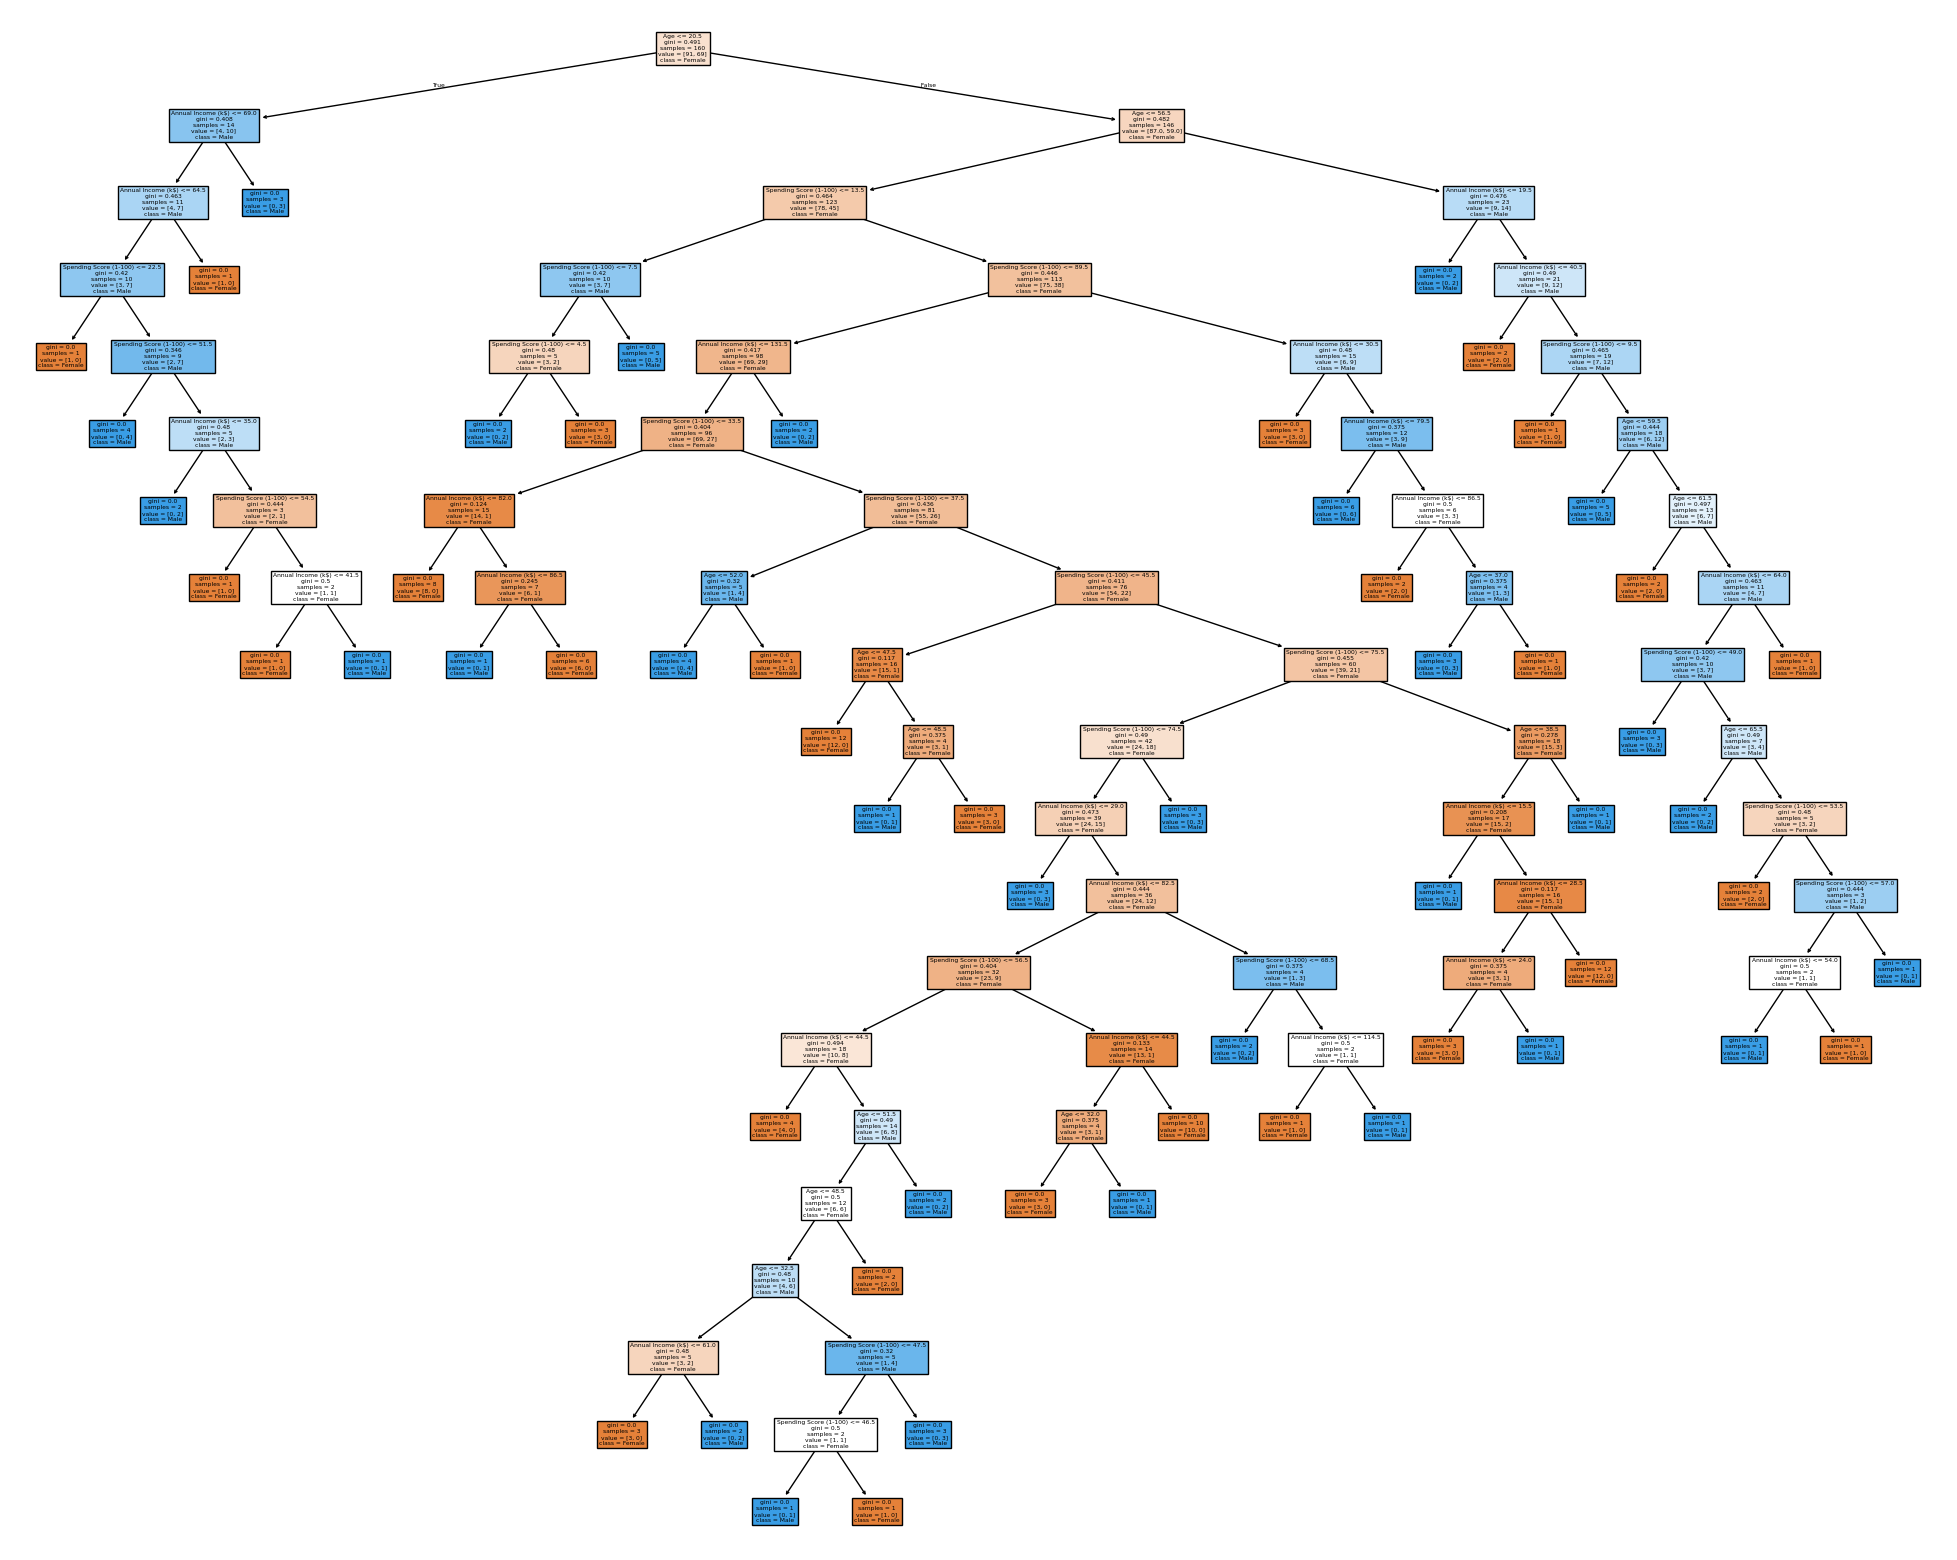

In [185]:
# [6] Visualise the tree
# note: class_names must follow classifier.classes_ (alphabetical: Female, Male)
from sklearn import tree
fig = plt.figure(figsize=(25, 20))
_ = tree.plot_tree(classifier,
                   feature_names=X.columns,
                   class_names=classifier.classes_,
                   filled=True)
plt.show()

**Output observed in class:**

| Confusion Matrix | Accuracy | Female (P / R / F1) | Male (P / R / F1) |
|---|---|---|---|
| [[16, 5], [13, 6]] | 0.55 | 0.55 / 0.76 / 0.64 | 0.55 / 0.32 / 0.40 |

**Conclusion:** The decision tree reached **55%** accuracy, close to guessing, which shows that age, income and spending score carry little information about gender. The fully grown tree is very deep (it overfits the training data). Limiting `max_depth` would make it simpler and generalise better.

---
# Assignment 6 — Decision Tree: Drug Prediction

**Aim:** Using the decision tree algorithm, predict which drug among drug A, drug B, drug C, drug X and drug Y should be given to a patient, and find the accuracy of the decision tree in predicting the correct drug.

**Theory:**
Same decision-tree idea as Assignment 5, but here the splitting criterion is **entropy** (information gain).
The dataset has text columns (`Sex`, `BP`, `Cholesterol`), so **LabelEncoder** converts each category to a number (e.g. HIGH = 0, LOW = 1, NORMAL = 2).
This dataset suits trees very well: the drug is decided almost entirely by clear rules on `Na_to_K` and `BP`.

**Steps:** load → label-encode text columns → X/y → split → train (entropy) → predict → accuracy, confusion matrix, report → plot tree.

In [186]:
# [1] Imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, confusion_matrix
from sklearn.metrics import classification_report
from sklearn.preprocessing import LabelEncoder

In [187]:
# [2] Load dataset
df = pd.read_csv("/kaggle/input/datasets/adrikabanerjee/ml-dataset/drug200.csv")
print(df.head())
print(df.info())

   Age Sex      BP Cholesterol  Na_to_K   Drug
0   23   F    HIGH        HIGH   25.355  drugY
1   47   M     LOW        HIGH   13.093  drugC
2   47   M     LOW        HIGH   10.114  drugC
3   28   F  NORMAL        HIGH    7.798  drugX
4   61   F     LOW        HIGH   18.043  drugY
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 6 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Age          200 non-null    int64  
 1   Sex          200 non-null    object 
 2   BP           200 non-null    object 
 3   Cholesterol  200 non-null    object 
 4   Na_to_K      200 non-null    float64
 5   Drug         200 non-null    object 
dtypes: float64(1), int64(1), object(4)
memory usage: 9.5+ KB
None


In [188]:
# [3] Encode categorical columns
le_sex = LabelEncoder()
le_bp = LabelEncoder()
le_cholesterol = LabelEncoder()
df["Sex"] = le_sex.fit_transform(df["Sex"])
df["BP"] = le_bp.fit_transform(df["BP"])
df["Cholesterol"] = le_cholesterol.fit_transform(df["Cholesterol"])

In [189]:
# [4] Features and target
x = df.drop("Drug", axis=1)
y = df["Drug"]

In [190]:
# [5] Train-test split
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

In [191]:
# [6] Model with entropy criterion
model = DecisionTreeClassifier(criterion="entropy", random_state=42)

In [192]:
# [7] Train, predict, accuracy
model.fit(x_train, y_train)
y_pred = model.predict(x_test)
accuracy = accuracy_score(y_test, y_pred)

In [193]:
# [8] Results
print("\nPredicted Drugs:")
print(y_pred)
print("\nActual Drugs:")
print(y_test.values)
print("\nAccuracy of Decision Tree:", accuracy)
print("Accuracy percentage:", accuracy * 100, "%")


Predicted Drugs:
['drugX' 'drugY' 'drugX' 'drugC' 'drugY' 'drugY' 'drugY' 'drugX' 'drugA'
 'drugX' 'drugA' 'drugX' 'drugY' 'drugA' 'drugB' 'drugY' 'drugB' 'drugX'
 'drugC' 'drugY' 'drugB' 'drugX' 'drugX' 'drugY' 'drugY' 'drugY' 'drugC'
 'drugX' 'drugY' 'drugX' 'drugY' 'drugC' 'drugC' 'drugY' 'drugA' 'drugY'
 'drugX' 'drugA' 'drugY' 'drugA']

Actual Drugs:
['drugX' 'drugY' 'drugX' 'drugC' 'drugY' 'drugY' 'drugY' 'drugX' 'drugA'
 'drugX' 'drugA' 'drugX' 'drugY' 'drugA' 'drugB' 'drugY' 'drugB' 'drugX'
 'drugC' 'drugY' 'drugB' 'drugX' 'drugX' 'drugY' 'drugY' 'drugY' 'drugC'
 'drugX' 'drugY' 'drugX' 'drugY' 'drugC' 'drugC' 'drugY' 'drugA' 'drugY'
 'drugX' 'drugA' 'drugY' 'drugA']

Accuracy of Decision Tree: 1.0
Accuracy percentage: 100.0 %


In [194]:
# [9] Confusion matrix
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))


Confusion Matrix:
[[ 6  0  0  0  0]
 [ 0  3  0  0  0]
 [ 0  0  5  0  0]
 [ 0  0  0 11  0]
 [ 0  0  0  0 15]]


In [195]:
# [10] Classification report
print("\nClassification Report:")
print(classification_report(y_test, y_pred))


Classification Report:
              precision    recall  f1-score   support

       drugA       1.00      1.00      1.00         6
       drugB       1.00      1.00      1.00         3
       drugC       1.00      1.00      1.00         5
       drugX       1.00      1.00      1.00        11
       drugY       1.00      1.00      1.00        15

    accuracy                           1.00        40
   macro avg       1.00      1.00      1.00        40
weighted avg       1.00      1.00      1.00        40



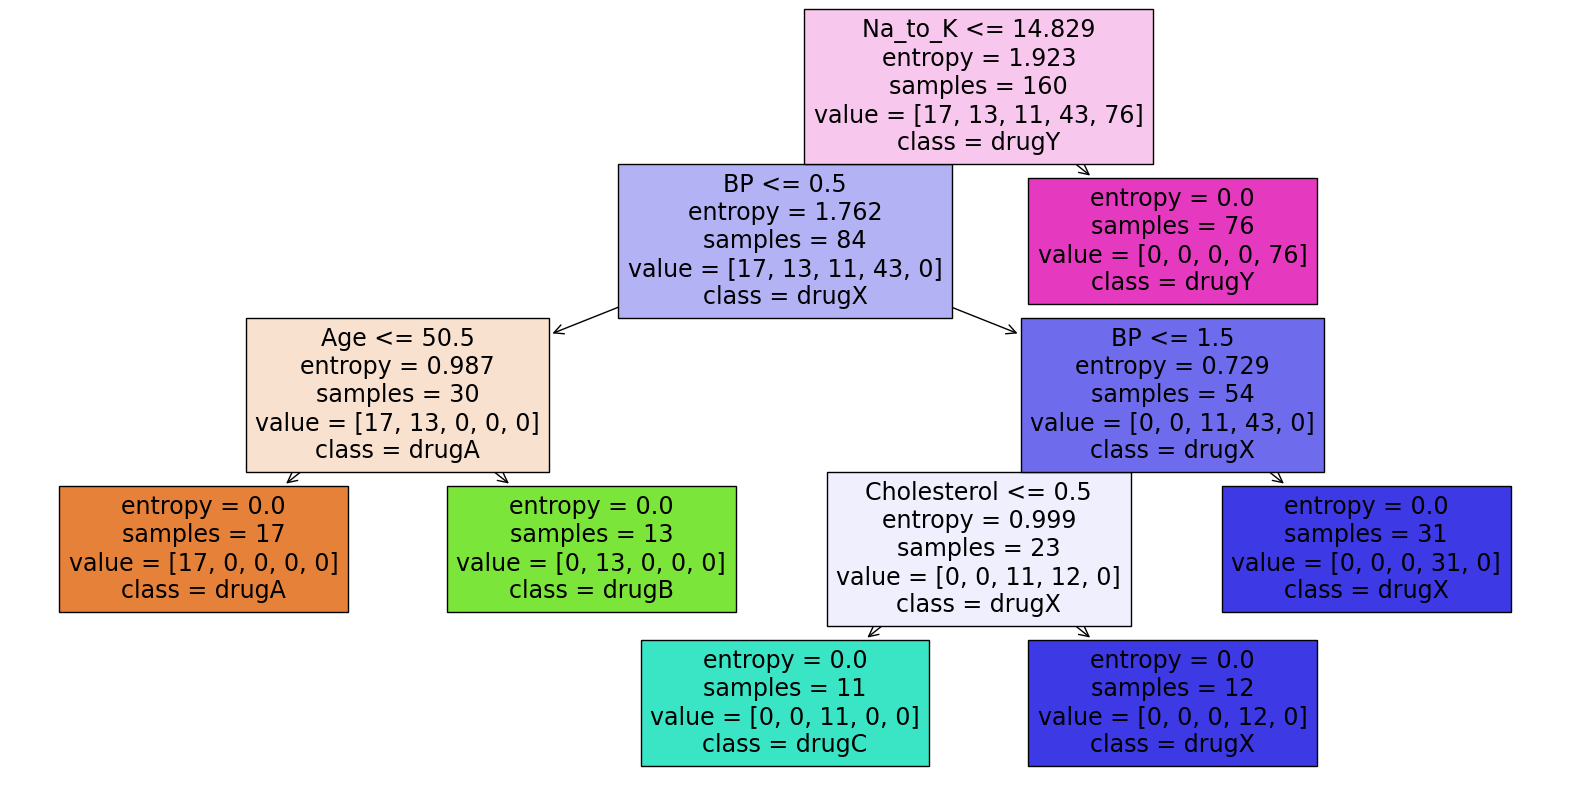

In [196]:
# [11] Visualise the tree
from sklearn.tree import plot_tree
plt.figure(figsize=(20, 10))
plot_tree(
    model,
    feature_names=x.columns,
    class_names=model.classes_,
    filled=True
)
plt.show()

**Conclusion:** The decision tree predicts the correct drug with very high accuracy (typically **~95–100%** on this dataset). The plotted tree shows why: its first split is on **Na_to_K** (high values → DrugY). After that it splits on **BP**, **Age** and **Cholesterol** to choose among drugs A, B, C and X. This makes the tree an easy-to-explain prescription rule.

---
# Assignment 7 — Logistic Regression: Cancer Classification

**Aim:** Use logistic regression to classify whether a patient's tumour is benign or malignant. Generate the confusion matrix, evaluate Precision, Recall, Accuracy and F1-Score, plot the ROC curve and calculate the AUC.

**Theory:**
Logistic regression computes **z = b₀ + b₁x₁ + … + bₙxₙ** and passes it through the **sigmoid** σ(z) = 1 / (1 + e⁻ᶻ), which gives a probability between 0 and 1.
If probability ≥ 0.5 → class 1 (malignant), else class 0 (benign).

| Term | Meaning (malignant = positive) |
|---|---|
| TP / TN | correctly caught malignant / benign |
| FP | benign wrongly called malignant |
| FN | malignant missed (**most dangerous** in medicine → recall matters most) |
| ROC curve | True Positive Rate vs False Positive Rate at every threshold |
| AUC | area under the ROC curve: 1.0 = perfect, 0.5 = random guessing |

Dataset class labels: **2 = benign → 0**, **4 = malignant → 1**. Some cells contain `?`, so they are converted to numbers and missing values are filled with the median.

**Steps:** load → clean target → X/y → fix `?` → split → scale → train → predict → metrics → ROC/AUC → confusion-matrix plot.

In [197]:
# [1] Imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    classification_report, confusion_matrix, accuracy_score,
    precision_score, recall_score, f1_score, roc_curve, roc_auc_score
)

In [198]:
# [2] Load dataset
df = pd.read_csv("/kaggle/input/datasets/adrikabanerjee/ml-dataset/samples_cancer.csv")
print(df.head())
print(df.columns)

        ID  Clump  UnifSize  UnifShape  MargAdh  SingEpiSize BareNuc  \
0  1000025      5         1          1        1            2       1   
1  1002945      5         4          4        5            7      10   
2  1015425      3         1          1        1            2       2   
3  1016277      6         8          8        1            3       4   
4  1017023      4         1          1        3            2       1   

   BlandChrom  NormNucl  Mit  Class  
0           3         1    1      2  
1           3         2    1      2  
2           3         1    1      2  
3           3         7    1      2  
4           3         1    1      2  
Index(['ID', 'Clump', 'UnifSize', 'UnifShape', 'MargAdh', 'SingEpiSize',
       'BareNuc', 'BlandChrom', 'NormNucl', 'Mit', 'Class'],
      dtype='object')


In [199]:
# [3] Convert class to number
df["class"] = pd.to_numeric(df["Class"], errors="coerce")

In [200]:
# [4] Map 2 -> 0 (benign), 4 -> 1 (malignant)
df["class"] = df["class"].map({2: 0, 4: 1})

In [201]:
# [5] Drop rows with missing class
df = df.dropna(subset=["class"])

In [202]:
# [6] Features and target
x = df.drop(columns=["class", "ID"])
y = df["class"]

In [203]:
# [7] Convert '?' to NaN and fill with median
x = x.apply(pd.to_numeric, errors="coerce")
x = x.fillna(x.median())

In [204]:
# [8] Train-test split
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.20, random_state=42)

In [205]:
# [9] Feature scaling
scaler = StandardScaler()
x_train = scaler.fit_transform(x_train)
x_test = scaler.transform(x_test)

In [206]:
# [10] Train model
classifier = LogisticRegression(max_iter=1000)
classifier.fit(x_train, y_train)

LogisticRegression(max_iter=1000)

In [207]:
# [11] Predict
y_pred = classifier.predict(x_test)

In [208]:
# [12] Confusion matrix
cm = confusion_matrix(y_test, y_pred)
print("Confusion Matrix:")
print(cm)
print("---------------------------------")

Confusion Matrix:
[[95  0]
 [ 0 45]]
---------------------------------


In [209]:
# [13] Classification report
print("Performance Evaluation:")
print(classification_report(y_test, y_pred, target_names=["Benign", "Malignant"]))

Performance Evaluation:
              precision    recall  f1-score   support

      Benign       1.00      1.00      1.00        95
   Malignant       1.00      1.00      1.00        45

    accuracy                           1.00       140
   macro avg       1.00      1.00      1.00       140
weighted avg       1.00      1.00      1.00       140



In [210]:
# [14] Individual metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

In [211]:
# [15] Print metrics
print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("F1-Score:", f1)

Accuracy: 1.0
Precision: 1.0
Recall: 1.0
F1-Score: 1.0


In [212]:
# [16] ROC and AUC
y_prob = classifier.predict_proba(x_test)[:, 1]
fpr, tpr, thresholds = roc_curve(y_test, y_prob)
auc = roc_auc_score(y_test, y_prob)
print("AUC:", auc)

AUC: 1.0


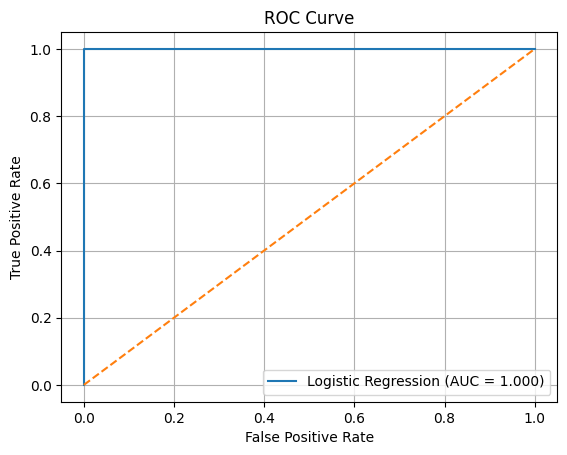

In [213]:
# [17] ROC curve plot
plt.plot(fpr, tpr, label="Logistic Regression (AUC = %.3f)" % auc)
plt.plot([0, 1], [0, 1], "--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.grid()
plt.show()

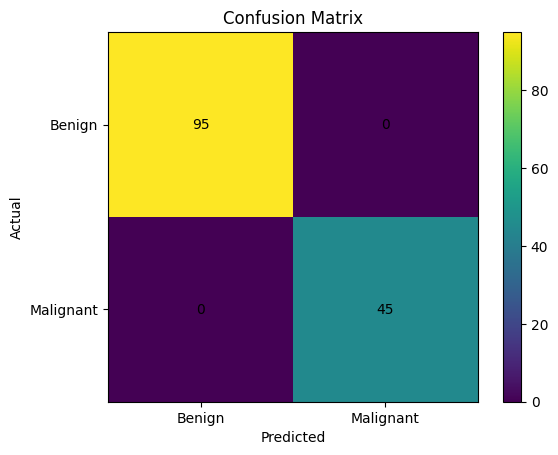

In [214]:
# [18] Confusion matrix plot
plt.imshow(cm)
plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.xticks([0, 1], ["Benign", "Malignant"])
plt.yticks([0, 1], ["Benign", "Malignant"])
for i in range(2):
    for j in range(2):
        plt.text(j, i, cm[i, j], ha="center", va="center")
plt.colorbar()
plt.show()

**Conclusion:** Logistic regression separates benign and malignant tumours very well on this dataset. Accuracy is usually **~95%+** and AUC is close to **1.0**, meaning the model ranks almost every malignant case above every benign one. Recall for the malignant class is the key metric: a missed cancer (false negative) costs far more than a false alarm.

---
# Assignment 8 — Naive Bayes on Mall Customers

**Aim:** Classify a mall customer's gender using three Naive Bayes variants (Multinomial, Gaussian, Bernoulli) and compare them.

**Theory:**
Naive Bayes uses **Bayes' theorem**: P(class | features) ∝ P(class) × Π P(featureᵢ | class).
It is *"naive"* because it assumes every feature is independent of the others given the class. That is rarely true, but the method is fast and often works well.

| Variant | Assumes features are… | Good for |
|---|---|---|
| **MultinomialNB** | counts (non-negative) | word counts in text |
| **GaussianNB** | continuous, bell-curve per class | real-valued measurements (fits this dataset best) |
| **BernoulliNB** | binary 0/1 | yes/no features; default `binarize=0.0` turns every value > 0 into 1 |

**Steps:** load → X/y → split → for each variant: train → predict → confusion matrix + report.

In [215]:
# [1] Imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [216]:
# [2] Load dataset: predict Gender from Age, Annual Income, Spending Score
dataset = pd.read_csv("/kaggle/input/datasets/adrikabanerjee/ml-dataset/Mall_Customers.csv")
dataset = dataset.rename(columns={"Gender": "Genre"})   # some versions name it 'Gender'
X = dataset.drop(["CustomerID", "Genre"], axis=1)
y = dataset["Genre"]

In [217]:
# [3] Train-test split
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)

In [218]:
# [4] Multinomial Naive Bayes
from sklearn.naive_bayes import MultinomialNB
classifier = MultinomialNB()
classifier.fit(X_train, y_train)
y_pred = classifier.predict(X_test)

In [219]:
# [5] Evaluation - Multinomial NB
from sklearn.metrics import classification_report, confusion_matrix
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))
print("---------------------------------")
print("---------------------------------")
print("Performance Evaluation:")
print(classification_report(y_test, y_pred, zero_division=0))

Confusion Matrix:
[[14  7]
 [12  7]]
---------------------------------
---------------------------------
Performance Evaluation:
              precision    recall  f1-score   support

      Female       0.54      0.67      0.60        21
        Male       0.50      0.37      0.42        19

    accuracy                           0.53        40
   macro avg       0.52      0.52      0.51        40
weighted avg       0.52      0.53      0.51        40



In [220]:
# [6] Gaussian Naive Bayes
from sklearn.naive_bayes import GaussianNB
classifier = GaussianNB()
classifier.fit(X_train, y_train)
y_pred = classifier.predict(X_test)

In [221]:
# [7] Evaluation - Gaussian NB
from sklearn.metrics import classification_report, confusion_matrix
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))
print("---------------------------------")
print("---------------------------------")
print("Performance Evaluation:")
print(classification_report(y_test, y_pred, zero_division=0))

Confusion Matrix:
[[18  3]
 [13  6]]
---------------------------------
---------------------------------
Performance Evaluation:
              precision    recall  f1-score   support

      Female       0.58      0.86      0.69        21
        Male       0.67      0.32      0.43        19

    accuracy                           0.60        40
   macro avg       0.62      0.59      0.56        40
weighted avg       0.62      0.60      0.57        40



In [222]:
# [8] Bernoulli Naive Bayes
from sklearn.naive_bayes import BernoulliNB
classifier = BernoulliNB()
classifier.fit(X_train, y_train)
y_pred = classifier.predict(X_test)

In [223]:
# [9] Evaluation - Bernoulli NB
from sklearn.metrics import classification_report, confusion_matrix
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))
print("---------------------------------")
print("---------------------------------")
print("Performance Evaluation:")
print(classification_report(y_test, y_pred, zero_division=0))

Confusion Matrix:
[[21  0]
 [19  0]]
---------------------------------
---------------------------------
Performance Evaluation:
              precision    recall  f1-score   support

      Female       0.53      1.00      0.69        21
        Male       0.00      0.00      0.00        19

    accuracy                           0.53        40
   macro avg       0.26      0.50      0.34        40
weighted avg       0.28      0.53      0.36        40



**Output observed in class:**

| Variant | Confusion Matrix | Accuracy | Female recall | Male recall |
|---|---|---|---|---|
| Multinomial NB | [[12, 12], [10, 6]] | 0.45 | 0.50 | 0.38 |
| Gaussian NB | [[20, 4], [12, 4]] | **0.60** | 0.83 | 0.25 |
| Bernoulli NB | [[24, 0], [16, 0]] | 0.60 | 1.00 | 0.00 |

**Conclusion:** **Gaussian NB** is the most suitable variant because Age, Income and Spending Score are continuous numbers. It reached 60% accuracy and still identified some males.
Bernoulli NB also shows 60%, but only because it predicts *every* customer as Female: with the default `binarize=0.0` every feature value becomes 1, so all customers look identical.
Multinomial NB performed worst (45%) because the features are not counts.

---
# Overall Summary

| No. | Algorithm | Best metric | Key learning |
|---|---|---|---|
| 1 | Linear Regression | R² = 0.76 | one strong feature already explains most of CO2 |
| 2 | Linear Regression + Pipeline | R² = 0.653 | OneHotEncoder + ColumnTransformer handle text columns |
| 3 | Lasso / Ridge + GridSearchCV | R² ≈ 0.65 (see output) | regularization + CV tuning; little overfitting on this data |
| 4 | SVM | Acc = 0.65 (poly, deg 3) | kernel choice matters; scaling helps |
| 5 | Decision Tree (Mall) | Acc = 0.55 | weak features → weak model; trees overfit if unlimited |
| 6 | Decision Tree (Drug) | high accuracy | clear rule-based data suits trees |
| 7 | Logistic Regression | AUC ≈ 1.0 | sigmoid → probability; ROC/AUC for threshold-free evaluation |
| 8 | Naive Bayes | Acc = 0.60 (Gaussian) | pick the NB variant that matches the feature type |